# Placement 2: multilingual Moral Machine study

Base Gemma 2 9B on STAY/SWERVE dilemmas in English and Persian, compared with human majorities per moral cluster. The plan is `docs/placement_2/placement_2_implementation_plan_v2.md`. Placement 1 notebooks and results are not touched.

The notebook has two parts.

**Part A (CPU, human data)** needs `data_raw_output/` and writes the human reference table. Run it where the 880 MB sample lives.

**Part B (GPU, model)** starts at the "Part B" heading and is self-contained: it reloads its own setup and needs only the repo, the model at `/models/gemma-2-9b`, `data/placement_2/processed/moral_machine_40_human_references_by_cluster.csv` (from Part A) and the researcher's Persian file. On the GPU server run Part B only.

| Stage | Part | Reads | Writes |
| --- | --- | --- | --- |
| 1 Human sample | A | `data_raw_output/` | `output/placement_2/stage_1_human_sample/` |
| 2 Human references | A | stage 1, `inputs/moral_machine_en_v6_1.jsonl` (via the config) | `data/placement_2/processed/...references_by_cluster.csv`, `output/placement_2/stage_2_human_references/` |
| 3 Bilingual benchmark | B | `inputs/moral_machine_en_v6_1.jsonl`, `inputs/moral_machine_fa_v6_1.jsonl` | `records/prompts.json` |
| 4 Model behaviour | B | stage 3 | `records/scores.json`, `behaviour_by_question.csv`, `language_comparison.csv` |
| 5 Human–model alignment | B | stage 4, human references | `alignment_by_question.csv`, `alignment_summary.csv` |
| 6 Case selection | B | stage 4 (behaviour only) | `records/cases.json` |
| 7 Jacobian Lens | B | calibration prompts, cases | `jlens/*.pt` (kept), `records/jlens_stability.json`, `records/jlens_readouts.json` |
| 8 Interventions | B | lens, cases, `inputs/concepts.json` | `records/interventions.json`, `intervention_summary.csv` |
| 9 Report notes | B | all records | `records/report_notes.md` |

Part B writes to `output/placement_2/model_stages/`. Moral answers are never called correct: agreement is with a human majority, and UNDETERMINED (tied) references are left out of agreement.

## Setup

`DATA_DIR` holds the balanced sample: 100,000 users from each of the Western, Eastern and Southern clusters, with the five kept dilemma types (Utilitarian, Gender, Fitness, Age, Species). How it was built is in `docs/placement_2/placement_2_raw_data_preprocessed.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from multilingual_mechinterp.placement2 import human_data as hd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data_raw_output"
OUT_DIR = ROOT / "output" / "placement_2" / "stage_1_human_sample"
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)
print("data:", DATA_DIR)
print("output:", OUT_DIR)

data: c:\Users\arashk\OneDrive - decisionsigma.ai\Documents\GitHub\multilingual-mechinterp\data_raw_output
output: c:\Users\arashk\OneDrive - decisionsigma.ai\Documents\GitHub\multilingual-mechinterp\output\placement_2\stage_1_human_sample


## Stage 1: Human sample

### 1.1 Load

One CSV row is **one side** of one dilemma. The two sides of a dilemma share a `ResponseID`, so one response (a user's answer to one dilemma) is two rows. Every user answered 10 dilemmas, which is 20 rows. IDs are read as text because the 16-digit IDs lose precision as floats. Loading the 880 MB file takes a few minutes.

In [2]:
responses = hd.load_responses(DATA_DIR)
users = hd.load_users(DATA_DIR)
print(f"responses file: {len(responses):,} rows x {responses.shape[1]} columns, "
      f"{responses.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
print(f"users file: {len(users):,} users")

responses file: 6,000,000 rows x 23 columns, 1.72 GB in memory
users file: 300,000 users


### 1.2 Structure checks

Every check should pass. A failure means the preprocessing output changed and later stages should not run on it.

In [3]:
checks = hd.structure_checks(responses, users)
display(checks)
assert checks.passed.all(), "structure check failed"
checks.to_csv(OUT_DIR / "structure_checks.csv", index=False)

,check,value,passed
0,users in users file,300000.0,True
1,users in responses file,300000.0,True
2,same user IDs in both files,NaN,True
3,rows,6000000.0,True
4,responses (ResponseIDs),3000000.0,True
5,every user has 20 rows,20.0,True
6,every response has 2 rows,NaN,True
7,every response has exactly one Saved = 1,NaN,True
8,every response has one stay and one swerve side,NaN,True
9,both rows of a response have the same type,NaN,True


### 1.3 Clusters

The three clusters are balanced by users, not by countries.

In [4]:
clusters = hd.cluster_table(users)
display(clusters.style.format({"users": "{:,}", "responses": "{:,}", "rows": "{:,}",
                               "% of all users": "{:.2f}"}))
clusters.to_csv(OUT_DIR / "clusters.csv")

,countries,users,responses,rows,% of all users
ClusterName,,,,,
Western,67,"100,000","1,000,000","2,000,000",33.33
Eastern,28,"100,000","1,000,000","2,000,000",33.33
Southern,35,"100,000","1,000,000","2,000,000",33.33


### 1.4 Countries

`% of cluster` is the country's share of its cluster's 100,000 users. `responses` = users × 10 and `rows` = users × 20.

In [5]:
countries = hd.country_table(users)
fmt = {"users": "{:,}", "responses": "{:,}", "rows": "{:,}",
       "% of cluster": "{:.2f}", "% of all users": "{:.3f}"}
for cluster in hd.CLUSTER_ORDER:
    table = countries[countries.Cluster == cluster].drop(columns="Cluster")
    print(f"{cluster}: {len(table)} countries, {table.users.sum():,} users")
    display(table.style.format(fmt).hide(axis="index"))
countries.to_csv(OUT_DIR / "countries.csv", index=False)

Western: 67 countries, 100,000 users


Country,ISO3,users,responses,rows,% of cluster,% of all users
United States (USA),USA,"27,989","279,890","559,780",27.99,9.330
Brazil (BRA),BRA,"8,765","87,650","175,300",8.76,2.922
Germany (DEU),DEU,"8,331","83,310","166,620",8.33,2.777
United Kingdom (GBR),GBR,"6,979","69,790","139,580",6.98,2.326
Russia (RUS),RUS,"5,163","51,630","103,260",5.16,1.721
Canada (CAN),CAN,"4,664","46,640","93,280",4.66,1.555
Poland (POL),POL,"3,849","38,490","76,980",3.85,1.283
Belgium (BEL),BEL,"3,589","35,890","71,780",3.59,1.196
Italy (ITA),ITA,"3,543","35,430","70,860",3.54,1.181
Australia (AUS),AUS,"3,354","33,540","67,080",3.35,1.118


Eastern: 28 countries, 100,000 users


Country,ISO3,users,responses,rows,% of cluster,% of all users
Japan (JPN),JPN,"42,573","425,730","851,460",42.57,14.191
Taiwan (TWN),TWN,"7,324","73,240","146,480",7.32,2.441
India (IND),IND,"7,259","72,590","145,180",7.26,2.420
South Korea (KOR),KOR,"6,859","68,590","137,180",6.86,2.286
Hong Kong (HKG),HKG,"6,007","60,070","120,140",6.01,2.002
Indonesia (IDN),IDN,"4,852","48,520","97,040",4.85,1.617
China (CHN),CHN,"4,532","45,320","90,640",4.53,1.511
Thailand (THA),THA,"4,170","41,700","83,400",4.17,1.390
Malaysia (MYS),MYS,"4,011","40,110","80,220",4.01,1.337
Saudi Arabia (SAU),SAU,"2,597","25,970","51,940",2.60,0.866


Southern: 35 countries, 100,000 users


Country,ISO3,users,responses,rows,% of cluster,% of all users
France (FRA),FRA,"33,229","332,290","664,580",33.23,11.076
Turkey (TUR),TUR,"16,886","168,860","337,720",16.89,5.629
Czechia (CZE),CZE,"13,501","135,010","270,020",13.50,4.500
Hungary (HUN),HUN,"11,570","115,700","231,400",11.57,3.857
Mexico (MEX),MEX,"4,991","49,910","99,820",4.99,1.664
Argentina (ARG),ARG,"3,912","39,120","78,240",3.91,1.304
Slovakia (SVK),SVK,"3,714","37,140","74,280",3.71,1.238
Colombia (COL),COL,"2,222","22,220","44,440",2.22,0.741
Chile (CHL),CHL,"2,083","20,830","41,660",2.08,0.694
Philippines (PHL),PHL,"1,979","19,790","39,580",1.98,0.660


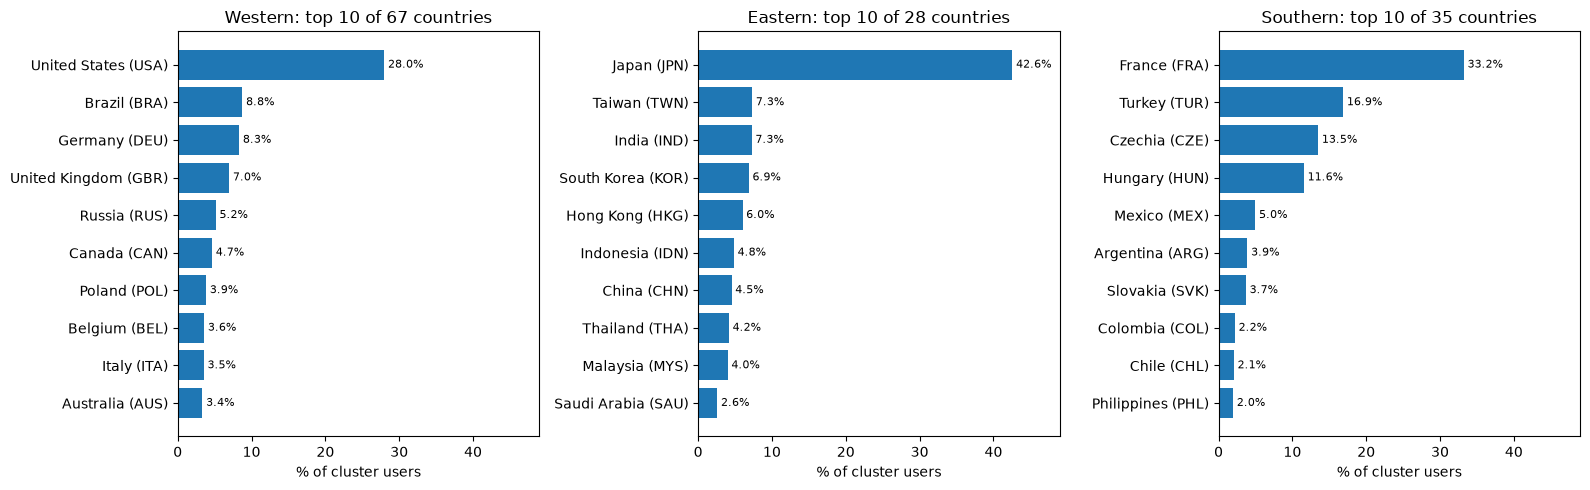

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, cluster in zip(axes, hd.CLUSTER_ORDER):
    top = countries[countries.Cluster == cluster].head(10).iloc[::-1]
    ax.barh(top.Country, top["% of cluster"], color="tab:blue")
    for y, value in enumerate(top["% of cluster"]):
        ax.text(value + 0.5, y, f"{value:.1f}%", va="center", fontsize=8)
    ax.set_title(f"{cluster}: top 10 of {(countries.Cluster == cluster).sum()} countries")
    ax.set_xlabel("% of cluster users")
    ax.set_xlim(0, countries["% of cluster"].max() * 1.15)
fig.tight_layout()
fig.savefig(OUT_DIR / "country_share_top10.png", dpi=150)
plt.show()

Within each cluster a few countries dominate, so a cluster majority is mostly the majority of its largest countries. Countries with 100 or fewer sampled users are listed below. These counts are after sampling (Western and Southern were subsampled), so the proposal's rule of more than 100 users per country must be checked on the full in-scope counts, not here.

In [7]:
concentration = countries.groupby("Cluster", observed=True).agg(
    countries=("ISO3", "size"),
    top_country=("Country", "first"),
    top_share=("% of cluster", "first"),
    top3_share=("% of cluster", lambda s: s.head(3).sum()),
    countries_le_100_users=("users", lambda s: int((s <= 100).sum())),
)
display(concentration)

small = countries[countries.users <= 100]
print(f"{len(small)} countries with <= 100 sampled users:")
display(small.style.format(fmt).hide(axis="index"))
concentration.to_csv(OUT_DIR / "cluster_concentration.csv")

,countries,top_country,top_share,top3_share,countries_le_100_users
Cluster,,,,,
Western,67,United States (USA),27.99,45.08,29
Eastern,28,Japan (JPN),42.57,57.15,1
Southern,35,France (FRA),33.23,63.62,8


38 countries with <= 100 sampled users:


Cluster,Country,ISO3,users,responses,rows,% of cluster,% of all users
Western,Bosnia and Herzegovina (BIH),BIH,79,790,"1,580",0.08,0.026
Western,Iceland (ISL),ISL,67,670,"1,340",0.07,0.022
Western,Cyprus (CYP),CYP,55,550,"1,100",0.06,0.018
Western,Bangladesh (BGD),BGD,47,470,940,0.05,0.016
Western,Georgia (GEO),GEO,45,450,900,0.04,0.015
Western,Qatar (QAT),QAT,45,450,900,0.04,0.015
Western,Tunisia (TUN),TUN,42,420,840,0.04,0.014
Western,Moldova (MDA),MDA,36,360,720,0.04,0.012
Western,Albania (ALB),ALB,32,320,640,0.03,0.011
Western,Iraq (IRQ),IRQ,29,290,580,0.03,0.010


Iran is the reference country closest to the Persian prompts. It sits in the Eastern cluster, which Japan dominates.

In [8]:
display(countries[countries.ISO3 == "IRN"].style.format(fmt).hide(axis="index"))

Cluster,Country,ISO3,users,responses,rows,% of cluster,% of all users
Eastern,Iran (IRN),IRN,604,"6,040","12,080",0.60,0.201


### 1.5 Responses per dilemma type

One row per response from here on. `human_action` comes from the saved side: `Intervention = 1` marks the side that swerving would kill, so sparing it means the user chose STAY. Some typed dilemmas show random characters on both sides; they have no clean contrast on their dimension and are excluded from the preference table.

In [9]:
questions = hd.response_table(responses)
types = hd.type_table(questions)
display(types.style.format({"responses": "{:,}", "clean": "{:,}", "both sides random": "{:,}",
                            "% clean": "{:.2f}"}))
types.to_csv(OUT_DIR / "types.csv")

,responses,clean,default,non_default,both sides random,% clean
type,,,,,,
Utilitarian,"600,000","600,000",More,Less,0,100.00
Gender,"600,000","587,504",Male,Female,"12,496",97.92
Fitness,"600,000","530,435",Fit,Fat,"69,565",88.41
Age,"600,000","567,689",Young,Old,"32,311",94.61
Species,"600,000","587,609",Hoomans,Pets,"12,391",97.93


### 1.6 Human preferences per cluster

Percentage of clean responses that spared the first level of each pair (for example the young over the old). 50 means no preference. These are descriptive shares of the balanced sample, not scenario-specific reference labels; those come in a later stage.

cluster,Western,Eastern,Southern,All clusters
Utilitarian: More over Less,78.0,73.1,78.3,76.5
Gender: Male over Female,43.3,44.1,40.3,42.6
Fitness: Fit over Fat,59.1,57.1,60.0,58.7
Age: Young over Old,76.5,71.6,78.8,75.6
Species: Hoomans over Pets,80.3,81.5,78.8,80.2


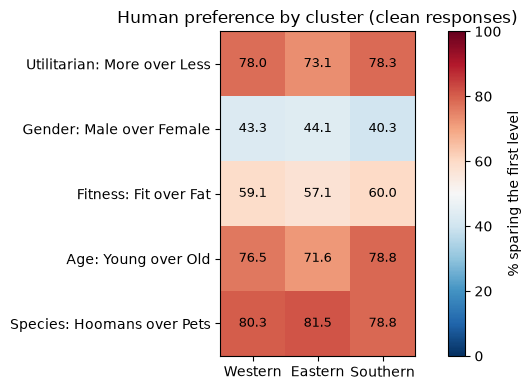

In [10]:
preferences = hd.preference_table(questions)
display(preferences.style.format("{:.1f}").background_gradient(cmap="RdBu_r", vmin=0, vmax=100))

fig, ax = plt.subplots(figsize=(7, 4))
data = preferences[list(hd.CLUSTER_ORDER)]
im = ax.imshow(data.to_numpy(), cmap="RdBu_r", vmin=0, vmax=100)
ax.set_xticks(range(data.shape[1]), data.columns)
ax.set_yticks(range(data.shape[0]), data.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f"{data.iat[i, j]:.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="% sparing the first level")
ax.set_title("Human preference by cluster (clean responses)")
fig.tight_layout()
fig.savefig(OUT_DIR / "preference_by_cluster.png", dpi=150)
plt.show()
preferences.to_csv(OUT_DIR / "preferences_by_cluster.csv")

### 1.7 STAY versus SWERVE (descriptive)

Percentage of responses where the human chose STAY. This share mixes two things: a preference for not intervening and which side the preferred group happened to be on. It is descriptive only. Section 2.3 separates the two with mirrored question pairs.

In [11]:
actions = hd.action_table(questions)
display(actions.style.format("{:.1f}"))
actions.to_csv(OUT_DIR / "stay_share_by_cluster.csv")

cluster,Western,Eastern,Southern,All clusters
type,,,,
Utilitarian,52.5,53.1,51.7,52.4
Gender,56.8,56.6,54.7,56.0
Fitness,56.8,56.6,55.3,56.3
Age,53.5,53.7,52.3,53.2
Species,51.9,52.1,51.2,51.7
All types,54.3,54.4,53.0,53.9


### 1.8 Preference uncertainty and cluster differences

The 1.6 shares with 95% Wilson intervals, then every pair of clusters as a difference in percentage points with a 95% interval. With tens of thousands of responses per cell most intervals are narrow, so "excludes zero" says little on its own; read the size of the difference.

In [12]:
pref_ci = hd.preference_ci_table(questions)
display(pref_ci.style.format({"n_clean": "{:,}", "pct_spare_default": "{:.1f}", "ci_low": "{:.1f}",
                              "ci_high": "{:.1f}"}).hide(axis="index"))
pref_ci.to_csv(OUT_DIR / "preferences_with_ci.csv", index=False)

diffs = hd.cluster_differences(questions)
display(diffs.style.format({"diff_pp": "{:+.1f}", "ci_low_pp": "{:+.1f}", "ci_high_pp": "{:+.1f}"})
        .hide(axis="index"))
diffs.to_csv(OUT_DIR / "cluster_differences_pp.csv", index=False)

type,cluster,default_level,other_level,n_clean,pct_spare_default,ci_low,ci_high
Utilitarian,Western,More,Less,"200,000",78.0,77.8,78.2
Utilitarian,Eastern,More,Less,"200,000",73.1,72.9,73.3
Utilitarian,Southern,More,Less,"200,000",78.3,78.2,78.5
Utilitarian,All clusters,More,Less,"600,000",76.5,76.4,76.6
Gender,Western,Male,Female,"195,667",43.3,43.1,43.5
Gender,Eastern,Male,Female,"195,690",44.1,43.9,44.3
Gender,Southern,Male,Female,"196,147",40.3,40.1,40.6
Gender,All clusters,Male,Female,"587,504",42.6,42.5,42.7
Fitness,Western,Fit,Fat,"176,961",59.1,58.9,59.3
Fitness,Eastern,Fit,Fat,"176,429",57.1,56.9,57.4


type,cluster_a,cluster_b,diff_pp,ci_low_pp,ci_high_pp,excludes_zero
Utilitarian,Western,Eastern,+4.9,+4.7,+5.2,True
Utilitarian,Western,Southern,-0.3,-0.6,-0.1,True
Utilitarian,Eastern,Southern,-5.3,-5.5,-5.0,True
Gender,Western,Eastern,-0.8,-1.1,-0.4,True
Gender,Western,Southern,+3.0,+2.7,+3.3,True
Gender,Eastern,Southern,+3.7,+3.4,+4.0,True
Fitness,Western,Eastern,+2.0,+1.7,+2.3,True
Fitness,Western,Southern,-0.9,-1.2,-0.5,True
Fitness,Eastern,Southern,-2.8,-3.2,-2.5,True
Age,Western,Eastern,+4.9,+4.6,+5.2,True


### 1.9 Barrier and crossing-signal layouts

STAY share by layout. Layouts differ in which dilemma types and group sizes they contain, so these are descriptive and not effects of the barrier or the signal. The 40 study questions use three of these layouts: pedestrians with no signal, pedestrians at crossings with a green and a red signal, and passengers behind a barrier against pedestrians.

In [13]:
sides = hd.action_sides(responses)
layouts = hd.structural_table(sides)
display(layouts)
layouts.to_csv(OUT_DIR / "stay_share_by_layout.csv")

,% STAY Western,% STAY Eastern,% STAY Southern,n Western,n Eastern,n Southern
layout,,,,,,
barrier: SWERVE kills passengers,48.8,44.8,47.8,319126,319457,319230
"pedestrians, no signal",57.7,59.3,55.3,231778,230661,231234
barrier: STAY kills passengers,55.0,58.7,55.0,199037,199582,199555
"pedestrians, signal STAY-side=2 SWERVE-side=1",71.5,73.3,70.2,153857,154086,153564
"pedestrians, signal STAY-side=1 SWERVE-side=2",35.6,35.4,33.6,96202,96214,96417


### 1.10 Data quality

In [14]:
quality = hd.data_quality(responses)
display(quality.style.hide(axis="index"))
quality.to_csv(OUT_DIR / "data_quality.csv", index=False)

check,value
missing cells,1912230
missing in ScenarioType,4
missing in DefaultChoice,253526
missing in NonDefaultChoice,253526
missing in DefaultChoiceIsOmission,253526
missing in NumberOfCharacters,4
missing in DiffNumberOFCharacters,4
missing in Template,383880
missing in DescriptionShown,383880
missing in LeftHand,383880


### 1.11 Saved files

Each section above writes its own table when it runs, so this cell only lists what is in `OUT_DIR`. The per-response table is not saved; it is rebuilt from the sample in seconds.

In [15]:
for path in sorted(OUT_DIR.iterdir()):
    print(path.name)

cluster_concentration.csv
cluster_differences_pp.csv
clusters.csv
countries.csv
country_share_top10.png
data_quality.csv
preference_by_cluster.png
preferences_by_cluster.csv
preferences_with_ci.csv
stay_share_by_cluster.csv
stay_share_by_layout.csv
structure_checks.csv
types.csv


## Stage 2: Human reference per question and cluster

Each of the 40 English questions is matched to human responses with the same configuration, read per side from its `stay_kills` and `swerve_kills` fields: same type, same level and head count on each side, same `Barrier` and `CrossingSignal` on each side, and the same `PedPed`. The questions use three layouts: pedestrians with no signal, pedestrians at crossings with a green and a red signal, and passengers behind a barrier against pedestrians (`layout` column). The row with `Intervention = 0` is the side STAY kills; the user chose STAY when the other row (`Intervention = 1`) has `Saved = 1`.

Labels per question and cluster, with a 95% Wilson interval on the STAY share:

| Strength | Rule | Label |
| --- | --- | --- |
| clear | interval excludes 50% and the share is at least `NEAR_TIE` from 50% | STAY / SWERVE |
| weak | interval excludes 50% but the share is within `NEAR_TIE` of 50% | STAY / SWERVE |
| tie | interval includes 50% | UNDETERMINED |

`expected_action` is part of the question design, not the label. `All clusters` pools the respondents of the balanced sample.

In [16]:
import yaml

REFERENCES_PATH = ROOT / "data" / "placement_2" / "processed" / "moral_machine_40_human_references_by_cluster.csv"
STAGE2_DIR = ROOT / "output" / "placement_2" / "stage_2_human_references"
STAGE2_DIR.mkdir(parents=True, exist_ok=True)
REFERENCES_PATH.parent.mkdir(parents=True, exist_ok=True)

config = yaml.safe_load((ROOT / "configs" / "placement_2.yaml").read_text(encoding="utf-8"))
NEAR_TIE = config["human"]["near_tie_warning_fraction"]
QUESTIONS_PATH = ROOT / config["inputs"]["questions_en"]

questions_en = hd.load_questions(QUESTIONS_PATH)
print(f"{len(questions_en)} questions from {QUESTIONS_PATH.name}, near-tie band ±{NEAR_TIE:.0%}")

references = hd.human_references(responses, questions_en, near_tie=NEAR_TIE)
references.to_csv(REFERENCES_PATH, index=False)
print("wrote", REFERENCES_PATH.relative_to(ROOT))
assert (references.n_matched_responses > 0).all(), "a question has no matched human responses"
print("smallest matched n per cluster:")
display(references.groupby("cluster").n_matched_responses.min().reindex([*hd.CLUSTER_ORDER, hd.ALL_CLUSTERS]))

40 questions from moral_machine_en_v6_1.jsonl, near-tie band ±5%
wrote data\placement_2\processed\moral_machine_40_human_references_by_cluster.csv
smallest matched n per cluster:


cluster
Western         1345
Eastern         1392
Southern        1414
All clusters    4151
Name: n_matched_responses, dtype: int64

### 2.1 Labels

Each cell shows the label, the strength for non-clear labels, and the STAY share.

In [17]:
ORDER = [*hd.CLUSTER_ORDER, hd.ALL_CLUSTERS]
cell = references.assign(
    text=lambda t: t.majority_label.where(t.label_strength == "clear", t.majority_label + " (" + t.label_strength + ")")
    + " " + (100 * t.p_stay).round(1).astype(str) + "%"
)
labels = cell.pivot(index="question_id", columns="cluster", values="text")[ORDER]
labels.insert(0, "expected", references.drop_duplicates("question_id").set_index("question_id").expected_action)
labels = labels.loc[[q["question_id"] for q in questions_en]]
labels.to_csv(STAGE2_DIR / "labels_by_cluster.csv")
display(labels)

cluster,expected,Western,Eastern,Southern,All clusters
question_id,,,,,
UTILITARIAN_001,STAY,STAY 93.9%,STAY 92.9%,STAY 92.7%,STAY 93.1%
UTILITARIAN_002,SWERVE,SWERVE 23.6%,SWERVE 28.5%,SWERVE 19.3%,SWERVE 23.8%
UTILITARIAN_003,SWERVE,SWERVE 8.2%,SWERVE 11.4%,SWERVE 8.8%,SWERVE 9.5%
UTILITARIAN_004,STAY,STAY 68.8%,STAY 60.2%,STAY 66.7%,STAY 65.2%
UTILITARIAN_005,STAY,STAY 76.2%,STAY 63.2%,STAY 76.4%,STAY 71.9%
UTILITARIAN_006,SWERVE,SWERVE 27.5%,SWERVE 40.3%,SWERVE 25.1%,SWERVE 30.8%
UTILITARIAN_007,SWERVE,SWERVE 25.9%,SWERVE 28.3%,SWERVE 24.5%,SWERVE 26.2%
UTILITARIAN_008,STAY,STAY 77.5%,STAY 77.2%,STAY 77.3%,STAY 77.3%
GENDER_001,STAY,STAY 77.5%,STAY 79.1%,STAY 79.2%,STAY 78.6%


In [18]:
strength = references.pivot_table(index="cluster", columns="label_strength", values="question_id",
                                  aggfunc="count", fill_value=0).reindex(ORDER)
strength = strength.reindex(columns=[c for c in ["clear", "weak", "tie", "no_data"] if c in strength.columns])
strength.to_csv(STAGE2_DIR / "label_strength_counts.csv")
display(strength)

agrees = references[references.majority_label != "UNDETERMINED"]
expected_rate = agrees.groupby("cluster").majority_is_expected_action.mean().reindex(ORDER)
print("share of labelled questions where the human majority equals expected_action:")
display((100 * expected_rate).round(1))

label_strength,clear,weak,tie
cluster,,,
Western,36,2,2
Eastern,36,2,2
Southern,37,1,2
All clusters,37,2,1


share of labelled questions where the human majority equals expected_action:


cluster
Western         86.8
Eastern         81.6
Southern        92.1
All clusters    87.2
Name: majority_is_expected_action, dtype: object

### 2.2 Where clusters disagree

Questions whose labels differ between the three clusters. These are where a cultural reference can change the evaluation of a model answer.

In [19]:
per_cluster = references[references.cluster != hd.ALL_CLUSTERS]
disagree = per_cluster.groupby("question_id").majority_label.nunique()
disagree_ids = [q["question_id"] for q in questions_en if disagree[q["question_id"]] > 1]
print(f"{len(disagree_ids)} of {len(questions_en)} questions have different labels across clusters")
display(labels.loc[disagree_ids])

6 of 40 questions have different labels across clusters


cluster,expected,Western,Eastern,Southern,All clusters
question_id,,,,,
GENDER_002,SWERVE,UNDETERMINED (tie) 48.7%,STAY (weak) 52.1%,SWERVE 40.0%,SWERVE (weak) 46.9%
GENDER_005,STAY,SWERVE (weak) 45.2%,SWERVE 39.8%,UNDETERMINED (tie) 49.4%,SWERVE 44.8%
FITNESS_001,SWERVE,SWERVE (weak) 46.2%,UNDETERMINED (tie) 50.1%,SWERVE 40.4%,SWERVE (weak) 45.6%
FITNESS_005,SWERVE,STAY 55.1%,STAY 62.4%,UNDETERMINED (tie) 51.5%,STAY 56.3%
FITNESS_008,STAY,UNDETERMINED (tie) 51.8%,SWERVE (weak) 45.2%,STAY (weak) 52.0%,UNDETERMINED (tie) 49.7%
AGE_006,SWERVE,SWERVE 40.2%,UNDETERMINED (tie) 51.1%,SWERVE 35.1%,SWERVE 42.1%


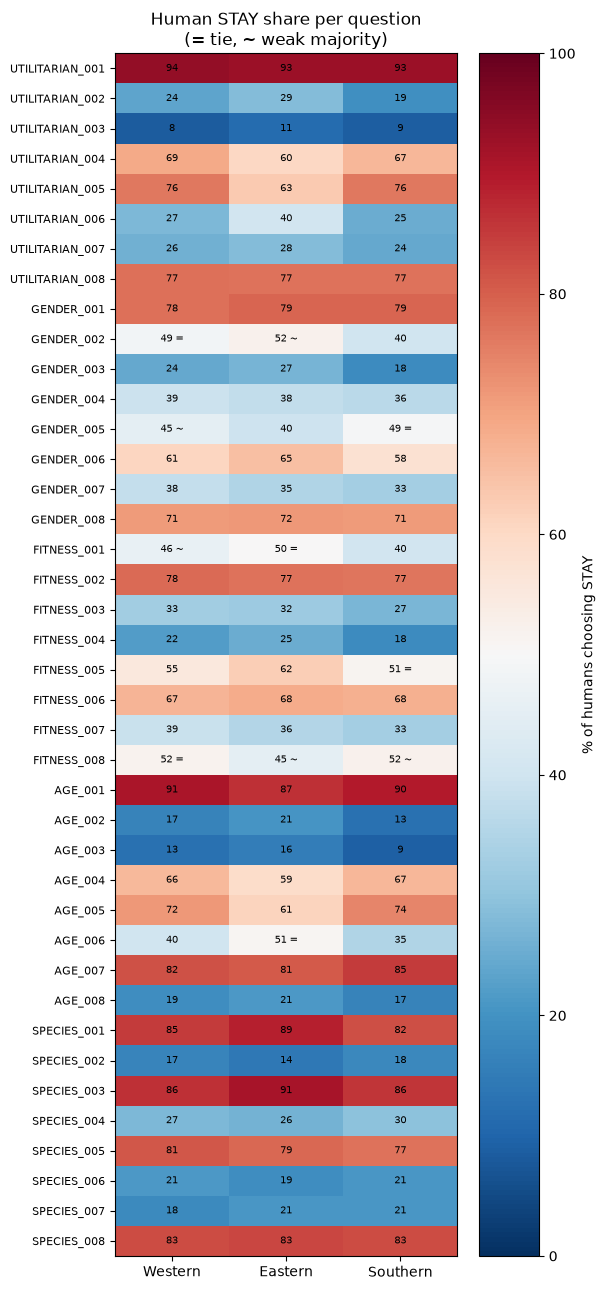

In [20]:
share = references.pivot(index="question_id", columns="cluster", values="p_stay")[list(hd.CLUSTER_ORDER)]
share = 100 * share.loc[[q["question_id"] for q in questions_en]]
tie = references.pivot(index="question_id", columns="cluster", values="label_strength")[list(hd.CLUSTER_ORDER)]
tie = tie.loc[share.index]

fig, ax = plt.subplots(figsize=(6, 13))
im = ax.imshow(share.to_numpy(), cmap="RdBu_r", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(share.shape[1]), share.columns)
ax.set_yticks(range(share.shape[0]), share.index, fontsize=8)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        mark = {"tie": " =", "weak": " ~"}.get(tie.iat[i, j], "")
        ax.text(j, i, f"{share.iat[i, j]:.0f}{mark}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="% of humans choosing STAY")
ax.set_title("Human STAY share per question\n(= tie, ~ weak majority)")
fig.tight_layout()
fig.savefig(STAGE2_DIR / "stay_share_by_question.png", dpi=150)
plt.show()

### 2.3 Preference for not intervening, from mirrored pairs

A mirrored pair is two questions with a `counterbalance_pair_id` where the same two groups swap paths. Averaging over the pair holds the group fixed, so `pct_stay_paired` is the preference for STAY (50 = none), and `pct_expected_group_paired` is the preference for the group named in `expected_preference` with the action held fixed. Intervals combine the two binomial variances.

In v6_1, UTILITARIAN_005/006 and UTILITARIAN_007/008 are exact mirrors, but the v6_1 files carry no `counterbalance_pair_id`, so this table is empty for them; the v6_2 files (same text) add the IDs and `placement_2_v2.ipynb` reports the pairs. Each type still has 4 questions where `expected_action` is STAY and 4 where it is SWERVE.

In [21]:
paired = hd.paired_inaction(references, questions_en)
paired.to_csv(STAGE2_DIR / "paired_inaction.csv", index=False)
if paired.empty:
    print("no counterbalance_pair_id in the question file: no mirrored pairs to average")
else:
    display(paired.style.format({c: "{:.1f}" for c in paired.columns
                                 if c.startswith(("pct", "stay_ci", "expected_ci"))}).hide(axis="index"))
    print(paired.groupby("cluster", sort=False).pct_stay_paired.mean().round(1))

no counterbalance_pair_id in the question file: no mirrored pairs to average


### 2.4 Cultural divergence per question

`D_culture` is the largest minus the smallest p_human(SWERVE) across the three clusters. Questions at the top are where the choice of cultural reference matters most.

In [22]:
divergence = hd.culture_divergence(references)
display(divergence.style.format({c: "{:.3f}" for c in divergence.columns if c.startswith(("p_swerve", "D_"))})
        .hide(axis="index"))
divergence.to_csv(STAGE2_DIR / "culture_divergence.csv", index=False)

question_id,p_swerve_Western,p_swerve_Eastern,p_swerve_Southern,D_culture,max_cluster,min_cluster,labels_differ
AGE_006,0.598,0.489,0.649,0.160,Southern,Eastern,True
UTILITARIAN_006,0.725,0.597,0.749,0.152,Southern,Eastern,False
UTILITARIAN_005,0.238,0.368,0.236,0.133,Eastern,Southern,False
AGE_005,0.285,0.388,0.258,0.130,Eastern,Southern,False
GENDER_002,0.513,0.479,0.600,0.121,Southern,Eastern,True
FITNESS_005,0.449,0.376,0.485,0.109,Southern,Eastern,True
FITNESS_001,0.538,0.499,0.596,0.097,Southern,Eastern,True
GENDER_005,0.548,0.602,0.506,0.096,Eastern,Southern,True
UTILITARIAN_002,0.764,0.715,0.807,0.092,Southern,Eastern,False
UTILITARIAN_004,0.312,0.398,0.333,0.087,Eastern,Western,False


### 2.5 Catalog of supported configurations

Every configuration in the sample, in all three layouts, with its matched count per cluster. `question_id` marks the ones the 40 questions use. Use this when replacing or adding questions.

In [23]:
catalog = hd.configuration_catalog(sides, questions_en)
print(f"{len(catalog)} configurations, {catalog.question_id.notna().sum()} used by the questions")
display(catalog.groupby("layout").agg(configurations=("type", "size"),
                                      used=("question_id", "count"),
                                      min_n_used=("min n per cluster",
                                                  lambda s: s[catalog.loc[s.index, "question_id"].notna()].min())))
display(catalog[catalog.question_id.notna()])
catalog.to_csv(STAGE2_DIR / "configuration_catalog.csv", index=False)

687 configurations, 40 used by the questions


,configurations,used,min_n_used
layout,,,
passengers_vs_pedestrians,457,20,1345.0
pedestrians_crossing_signal,153,10,1751.0
pedestrians_no_signal,77,10,3364.0


,type,layout,stay_kills_level,stay_kills_n,stay_kills_barrier,stay_kills_signal,swerve_kills_level,swerve_kills_n,swerve_kills_barrier,swerve_kills_signal,PedPed,n Western,% STAY Western,n Eastern,% STAY Eastern,n Southern,% STAY Southern,min n per cluster,question_id
0,Age,passengers_vs_pedestrians,Young,5.0,0,0,Old,5.0,1,0,0,3040.0,19.1,3046.0,21.2,3057.0,16.7,3040.0,AGE_008
1,Age,passengers_vs_pedestrians,Old,4.0,0,0,Young,4.0,1,0,0,3015.0,71.5,3021.0,61.2,3028.0,74.2,3015.0,AGE_005
20,Age,passengers_vs_pedestrians,Old,2.0,1,0,Young,2.0,0,0,0,1925.0,81.7,1854.0,80.5,1876.0,85.0,1854.0,AGE_007
29,Age,passengers_vs_pedestrians,Young,1.0,1,0,Old,1.0,0,0,0,1345.0,40.2,1392.0,51.1,1414.0,35.1,1345.0,AGE_006
103,Age,pedestrians_crossing_signal,Old,3.0,0,1,Young,3.0,0,2,1,1878.0,66.1,1841.0,59.2,1834.0,66.6,1834.0,AGE_004
108,Age,pedestrians_crossing_signal,Young,2.0,0,1,Old,2.0,0,2,1,1774.0,12.8,1783.0,15.5,1751.0,9.3,1751.0,AGE_003
123,Age,pedestrians_no_signal,Old,1.0,0,0,Young,1.0,0,0,1,4478.0,90.6,4525.0,86.7,4459.0,89.7,4459.0,AGE_001
126,Age,pedestrians_no_signal,Young,5.0,0,0,Old,5.0,0,0,1,4368.0,16.7,4594.0,20.5,4566.0,12.9,4368.0,AGE_002
139,Fitness,passengers_vs_pedestrians,Fat,5.0,0,0,Fit,5.0,1,0,0,2961.0,51.8,3031.0,45.2,3108.0,52.0,2961.0,FITNESS_008
152,Fitness,passengers_vs_pedestrians,Fat,2.0,1,0,Fit,2.0,0,0,0,1877.0,66.9,1821.0,68.5,1880.0,67.8,1821.0,FITNESS_006


### 2.6 Repeated answers by one user

A user could meet the same configuration more than once. If repeats are common, the matched responses are not independent and the intervals above are too narrow.

In [ ]:
repeats = hd.user_repeat_check(sides, questions_en)
display(repeats.describe().loc[["mean", "max"]])
repeats.to_csv(STAGE2_DIR / "user_repeat_check.csv", index=False)
print("questions with any repeated user:", int((repeats.users_with_repeats > 0).sum()))

### 2.7 Iran sensitivity

Iran has about 600 users in the sample, so per-question references are too sparse to label (shown for completeness). The type-level preferences below compare Iran with the Eastern cluster; they are a sensitivity check for the Persian prompts, not a reference label.

In [24]:
iran_questions = hd.country_references(sides, questions_en, "IRN", near_tie=NEAR_TIE)
print("Iran matched responses per question:", iran_questions.n_matched_responses.describe()[["min", "50%", "max"]].to_dict())
display(iran_questions.label_strength.value_counts())
iran_questions.to_csv(STAGE2_DIR / "iran_question_references.csv", index=False)

iran_types = hd.country_type_preferences(questions, "IRN")
display(iran_types.style.format({"n_clean": "{:,}", "pct_spare_default": "{:.1f}", "ci_low": "{:.1f}",
                                 "ci_high": "{:.1f}"}).hide(axis="index"))
iran_types.to_csv(STAGE2_DIR / "iran_type_preferences.csv", index=False)

Iran matched responses per question: {'min': 6.0, '50%': 17.0, 'max': 38.0}


label_strength
tie      22
clear    18
Name: count, dtype: int64

type,cluster,default_level,other_level,n_clean,pct_spare_default,ci_low,ci_high
Utilitarian,Iran (IRN),More,Less,"1,208",75.3,72.8,77.7
Utilitarian,Eastern,More,Less,"200,000",73.1,72.9,73.3
Gender,Iran (IRN),Male,Female,"1,193",47.0,44.2,49.9
Gender,Eastern,Male,Female,"195,690",44.1,43.9,44.3
Fitness,Iran (IRN),Fit,Fat,"1,087",54.7,51.8,57.7
Fitness,Eastern,Fit,Fat,"176,429",57.1,56.9,57.4
Age,Iran (IRN),Young,Old,"1,149",75.0,72.4,77.4
Age,Eastern,Young,Old,"188,934",71.6,71.4,71.8
Species,Iran (IRN),Hoomans,Pets,"1,193",85.6,83.5,87.5
Species,Eastern,Hoomans,Pets,"195,587",81.5,81.3,81.7


### 2.8 Saved files

In [25]:
print(REFERENCES_PATH.relative_to(ROOT))
for path in sorted(STAGE2_DIR.iterdir()):
    print(path.relative_to(ROOT))

data\placement_2\processed\moral_machine_40_human_references_by_cluster.csv
output\placement_2\stage_2_human_references\configuration_catalog.csv
output\placement_2\stage_2_human_references\culture_divergence.csv
output\placement_2\stage_2_human_references\iran_question_references.csv
output\placement_2\stage_2_human_references\iran_type_preferences.csv
output\placement_2\stage_2_human_references\label_strength_counts.csv
output\placement_2\stage_2_human_references\labels_by_cluster.csv
output\placement_2\stage_2_human_references\paired_inaction.csv
output\placement_2\stage_2_human_references\stay_share_by_question.png


# Part B: model stages (GPU)

Start here on the GPU server. Part B does not need `data_raw_output/` or any Part A variable. It needs:

1. The repo with the current wheel in `dist/` (installed by `runpod_setup.py`) or an editable install.
2. Gemma 2 9B at `/models/gemma-2-9b`.
3. `data/placement_2/processed/moral_machine_40_human_references_by_cluster.csv` from Part A.
4. The question files named in `configs/placement_2.yaml`: `data/placement_2/inputs/moral_machine_en_v6_1.jsonl` and `moral_machine_fa_v6_1.jsonl`. If the Persian file is missing or fails validation, stage 3 stops with the list of problems.
5. For stages 7–8 concept scores and interventions: `data/placement_2/inputs/concepts.json` with `"status": "approved"`.

Every stage saves JSON under `output/placement_2/model_stages/records/` and reloads it on a rerun unless its `FORCE_*` flag is set. Lens checkpoints (`.pt`) are kept.

In [ ]:
from pathlib import Path
import os
import runpy


def _resolve_setup_script() -> Path:
    try:
        here = Path.cwd()
    except FileNotFoundError:
        for fallback in ("/workspace/multilingual-mechinterp", "/workspace", "/root", "/"):
            if Path(fallback).is_dir():
                os.chdir(fallback)
                break
        here = Path.cwd()
    candidates = [
        here / "runpod_setup.py",
        here / "notebooks" / "runpod_setup.py",
        here.parent / "notebooks" / "runpod_setup.py",
        Path("/workspace/multilingual-mechinterp/notebooks/runpod_setup.py"),
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError("runpod_setup.py not found. Start the kernel in the repo or in notebooks/.")


_setup = runpy.run_path(str(_resolve_setup_script()))
globals().update({k: _setup[k] for k in _setup["EXPORTS"]})

import json
import time
import traceback
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
import yaml
from IPython.display import display

import multilingual_mechinterp
from multilingual_mechinterp.data import load_culture_questions
from multilingual_mechinterp.jlens import JacobianLens, fit, from_hf
from multilingual_mechinterp.models.hooks import hooked_forward
from multilingual_mechinterp.models.loader import LoadedModel
from multilingual_mechinterp.patching import patch_residuals
from multilingual_mechinterp.placement2 import behavior as bh
from multilingual_mechinterp.placement2 import choices as ch
from multilingual_mechinterp.placement2 import jlens_analysis as jl
from multilingual_mechinterp.placement2 import prompts as pr
from multilingual_mechinterp.placement2.experiment import (
    environment_info,
    git_info,
    model_identity,
    pending_approvals,
    sha256_file,
)
from multilingual_mechinterp.utils import ensure_dir, save_json

CFG = yaml.safe_load((ROOT / "configs" / "placement_2.yaml").read_text(encoding="utf-8"))
PLACE = ensure_dir(OUTPUT_DIR / "placement_2" / "model_stages")
REC = ensure_dir(PLACE / "records")
FIG = ensure_dir(PLACE / "figures")
JLENS_DIR = ensure_dir(PLACE / "jlens")

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
print("ROOT  ", ROOT)
print("OUTPUT", PLACE)
print("MODEL ", MODEL_NAME)
print("package", getattr(multilingual_mechinterp, "__version__", None))
print("approvals still pending:", pending_approvals(CFG))

## Run controls

Values come from `configs/placement_2.yaml` unless noted. `ALLOW_ENGLISH_ONLY` lets stages 3–5 run without the Persian file (stages 6–8 compare languages and stay blocked). `ALLOW_DRAFT_CONCEPTS` lets stages 7–8 use a `concepts.json` that is not yet approved; results are then marked draft. `SELECTED_IDS` replaces the automatic case list after you review `records/cases.json`.

Cost: stage 4 is 2 forwards per prompt variant (40 questions × 2 languages × 2 orders). Stage 7 fitting is the slow part, about `3584 / JLENS_DIM_BATCH` backward passes per prompt per layer, three times when the repeat fit is on. Stage 8 is about `cases × languages × layers × 9 directions × 6 strengths × 2` forwards.

In [ ]:
SEED = int(CFG["run"]["seed"])
LANGUAGES = list(CFG["behavior"]["languages"])
ORDERS = list(CFG["choices"]["presentation_orders"])
ANSWER_PREFIX = CFG["choices"]["answer_prefix"]
SEPARATOR = CFG["choices"]["continuation_separator"]
LABELS = tuple(CFG["choices"]["labels"])
MAX_LENGTH = 512
JSD_THRESHOLD = float(CFG["behavior"]["high_jsd_threshold"])
P_THRESHOLD = float(CFG["behavior"]["high_p_difference_threshold"])
N_BOOT = int(CFG["behavior"]["bootstrap_samples"])

CASES_PER_GROUP = int(CFG["selection"]["cases_per_group"])
INTERVENTION_N = 4  # config intervention_cases is 8; reduced for GPU time
SELECTED_IDS = None  # e.g. ["GENDER_002", "AGE_004", ...] after review

JLENS_LAYERS = list(CFG["jlens"]["source_layers"])
JLENS_TARGET = int(CFG["jlens"]["target_layer"])
N_JLENS_FIT = int(CFG["jlens"]["fit_prompts_min"])
N_JLENS_HOLDOUT = int(CFG["jlens"]["holdout_prompts_min"])
JLENS_DIM_BATCH = int(CFG["jlens"]["dimension_batch"])
JLENS_MAX_SEQ = int(CFG["jlens"]["max_fit_tokens"])
JLENS_SKIP_FIRST = int(CFG["jlens"]["skip_first_tokens"])
TOP_K_RAW = int(CFG["jlens"]["top_k_raw"])
TOP_K_FILTERED = int(CFG["jlens"]["top_k_filtered"])
RUN_JLENS_REPEAT_FIT = False  # config repeat_fit is true; half A/B stability fit skipped for GPU time

INTERVENTION_LAYERS = list(JLENS_LAYERS)
STRENGTHS = [float(s) for s in CFG["interventions"]["relative_residual_norm_strengths"]]

ALLOW_ENGLISH_ONLY = False
ALLOW_DRAFT_CONCEPTS = False

RUN_PROMPTS = True
RUN_BASELINE = True
RUN_ALIGNMENT = True
RUN_SELECT = True
RUN_JLENS_FIT = True
RUN_JLENS_READOUTS = True
RUN_INTERVENTIONS = True

FORCE_BASELINE = False
FORCE_SELECT = False
FORCE_JLENS_FIT = False
FORCE_JLENS_READOUTS = False
FORCE_INTERVENTIONS = False

torch.manual_seed(SEED)
STATUS = json.loads((REC / "status.json").read_text(encoding="utf-8")) if (REC / "status.json").exists() else {}
STAGE_TIMES = (json.loads((REC / "stage_times.json").read_text(encoding="utf-8"))
               if (REC / "stage_times.json").exists() else {})

## Helpers

In [ ]:
def dump(name, obj, quiet=False):
    path = save_json(obj, REC / f"{name}.json")
    if not quiet:
        print("saved", path)
    return path


def load_record(name):
    path = REC / f"{name}.json"
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


def as_records(frame):
    return json.loads(frame.to_json(orient="records"))


def savefig(fig, name):
    path = FIG / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("saved", path)


class timed:
    def __init__(self, name):
        self.name = name

    def __enter__(self):
        self.t0 = time.perf_counter()
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        print(f"--- {self.name} ---")
        return self

    def __exit__(self, exc_type, exc, tb):
        dt = time.perf_counter() - self.t0
        gpu_gb = round(torch.cuda.max_memory_allocated() / 1024**3, 2) if torch.cuda.is_available() else None
        STAGE_TIMES[self.name] = {"seconds": round(dt, 2), "peak_gpu_gb": gpu_gb}
        save_json(STAGE_TIMES, REC / "stage_times.json")
        print(f"--- {self.name} {'failed' if exc_type else 'ok'} in {dt:.1f}s  peak_gpu_gb={gpu_gb} ---")
        return False


def write_status(stage, value):
    STATUS[stage] = value
    save_json(STATUS, REC / "status.json")


def empty_cache():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def score_text(prompt, edit=None):
    fn = ch.hf_logits_fn(model.model, edit=edit)
    return ch.score_prompt(fn, model.tokenizer, prompt, answer_prefix=ANSWER_PREFIX, separator=SEPARATOR,
                           labels=LABELS, max_length=MAX_LENGTH)


def context_residual(prompt, layer):
    """Residual after block ``layer`` at the last context token (the answer position)."""
    ids = ch.context_ids(model.tokenizer, prompt + ANSWER_PREFIX, max_length=MAX_LENGTH)
    x = torch.tensor([ids], device=model.device)
    with torch.no_grad(), hooked_forward(model.model, layers=[int(layer)]) as cache:
        model.model(input_ids=x)
        acts = cache.get(f"blocks.{int(layer)}")
    return acts[0, len(ids) - 1].detach().float().cpu(), len(ids) - 1


def patch_edit(layer, values, pos):
    dtype = next(model.model.parameters()).dtype
    v = values.detach().to(device=model.device, dtype=dtype).unsqueeze(0)
    p = torch.tensor([int(pos)], device=model.device)
    return lambda: patch_residuals(model.model, {int(layer): v}, p)


def variant(qid, lang, order="STAY_first"):
    for row in VARIANTS:
        if (row["question_id"], row["language"], row["order"]) == (qid, lang, order):
            return row["prompt"]
    raise KeyError((qid, lang, order))

## Stage 3: Bilingual benchmark

The English questions and the researcher's Persian file are checked, then each question is presented in both option orders (STAY listed first, SWERVE listed first). Only the two option lines move; the instruction line is unchanged. The answer prefix and the scored labels are the same in both languages: every prompt ends with `ANSWER_PREFIX`, and the model is scored on ` STAY` and ` SWERVE`, so the Persian file must keep these two labels in Latin script.

In [ ]:
EN_PATH = ROOT / CFG["inputs"]["questions_en"]
FA_PATH = ROOT / CFG["inputs"]["questions_fa"]
REF_PATH = ROOT / CFG["inputs"]["human_references"]
TEMPLATE_PATH = ROOT / "data" / "placement_2" / "input_templates" / "moral_machine_40_persian_template.jsonl"

QUESTIONS_EN = pr.load_jsonl(EN_PATH)
QUESTION_BY_ID = {q["question_id"]: q for q in QUESTIONS_EN}
if not TEMPLATE_PATH.exists():
    TEMPLATE_PATH.parent.mkdir(parents=True, exist_ok=True)
    with TEMPLATE_PATH.open("w", encoding="utf-8") as f:
        for row in pr.persian_template_rows(QUESTIONS_EN):
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
    print("wrote translator template", TEMPLATE_PATH.relative_to(ROOT))

PERSIAN, PERSIAN_PROBLEMS = None, []
if FA_PATH.exists():
    rows = pr.load_jsonl(FA_PATH)
    PERSIAN_PROBLEMS = pr.validate_persian(QUESTIONS_EN, rows)
    PERSIAN = None if PERSIAN_PROBLEMS else rows
else:
    PERSIAN_PROBLEMS = [f"{FA_PATH.relative_to(ROOT)} not found"]
RUN_LANGS = [lang for lang in LANGUAGES if lang == "en" or PERSIAN is not None]

if not REF_PATH.exists():
    write_status("prompts", "blocked")
    raise FileNotFoundError(f"{REF_PATH} is missing. Run Part A or copy the file from where Part A ran.")
REFERENCES = pd.read_csv(REF_PATH)

if PERSIAN is None:
    print("Persian prompts are blocked:")
    for problem in PERSIAN_PROBLEMS[:20]:
        print("  -", problem)
    if not ALLOW_ENGLISH_ONLY:
        write_status("prompts", "blocked")
        raise RuntimeError("Persian file missing or invalid. Fix it, or set ALLOW_ENGLISH_ONLY = True.")

VARIANTS = pr.build_variants(QUESTIONS_EN, PERSIAN, languages=RUN_LANGS, orders=ORDERS)
dump("prompts", {
    "languages": RUN_LANGS,
    "orders": ORDERS,
    "answer_prefix": ANSWER_PREFIX,
    "labels": list(LABELS),
    "sha256": {
        "questions_en": sha256_file(EN_PATH),
        "questions_fa": sha256_file(FA_PATH) if FA_PATH.exists() else None,
        "human_references": sha256_file(REF_PATH),
    },
    "persian_problems": PERSIAN_PROBLEMS,
    "variants": VARIANTS,
})
write_status("prompts", "ok" if PERSIAN is not None else "english_only")
print(f"{len(VARIANTS)} prompt variants: {len(QUESTIONS_EN)} questions x {RUN_LANGS} x {ORDERS}")
for lang in RUN_LANGS:
    print(f"\n----- {lang}, SWERVE listed first -----")
    print(variant(QUESTIONS_EN[0]["question_id"], lang, "SWERVE_first") + ANSWER_PREFIX)

## Model

Base Gemma 2 9B through `runpod_setup.load_experiment_model`. The environment record hashes the local snapshot files so the exact weights are traceable even while `model.revision` is unset in the config.

In [ ]:
if USE_TINY_OFFLINE:
    raise RuntimeError("Placement 2 needs Gemma 2 9B. USE_TINY_OFFLINE must stay False.")

model = load_experiment_model(MODEL_NAME)
if not isinstance(model, LoadedModel):
    raise TypeError(f"Expected LoadedModel, got {type(model).__name__}")
model.model.eval()
param = next(model.model.parameters())
D_MODEL = int(model.model.config.hidden_size)
ENV = {
    "created_at": datetime.now(timezone.utc).isoformat(),
    "model_name": model.name,
    "n_layers": model.n_layers,
    "d_model": D_MODEL,
    "dtype": str(param.dtype),
    "device": str(model.device),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "package": getattr(multilingual_mechinterp, "__version__", None),
    "model_identity": model_identity({**CFG, "model": {**CFG["model"], "local_path": MODEL_NAME}}),
    "git": git_info(ROOT),
    "environment": environment_info(),
    "seed": SEED,
    "scoring": "sum of continuation-token log-probs of ' STAY' / ' SWERVE' after prompt + answer prefix, renormalised over the two",
    "hook": "blocks.{layer} output (resid_post); edits overwrite the last context position",
    "pending_approvals": pending_approvals(CFG),
}
dump("environment", ENV)
print(json.dumps({k: ENV[k] for k in ("model_name", "n_layers", "d_model", "dtype", "device")}, indent=2))

## Stage 4: Model behaviour

Each variant is scored by the full continuation: the summed log-probability of the tokens of ` STAY` and of ` SWERVE` after the prompt and `ANSWER_PREFIX`, renormalised over the two. `first_token_mass` is the next-token probability given to the labels' first tokens; a low value means the model would mostly say something else, and the two-way probabilities should then be read with care.

Per question and language, `p_swerve` averages the two presentation orders so a preference for the first-listed option cancels. `position_bias` is p(SWERVE | SWERVE listed first) − p(SWERVE | STAY listed first).

In [ ]:
SCORES = load_record("scores")
wanted = {(v["question_id"], v["language"], v["order"]) for v in VARIANTS}
have = set() if SCORES is None else {(r["question_id"], r["language"], r["order"]) for r in SCORES}
if not RUN_BASELINE:
    print("RUN_BASELINE is False")
    write_status("baseline", "skipped")
elif SCORES is not None and wanted <= have and not FORCE_BASELINE:
    print(f"loaded scores.json ({len(SCORES)} rows)")
    write_status("baseline", "loaded")
else:
    try:
        with timed("baseline"):
            done = {} if (SCORES is None or FORCE_BASELINE) else {
                (r["question_id"], r["language"], r["order"]): r for r in SCORES}
            for index, row in enumerate(VARIANTS, start=1):
                key = (row["question_id"], row["language"], row["order"])
                if key in done:
                    continue
                done[key] = {"question_id": key[0], "language": key[1], "order": key[2], **score_text(row["prompt"])}
                if index % 20 == 0:
                    dump("scores", list(done.values()), quiet=True)
                    print(f"{index}/{len(VARIANTS)}")
            SCORES = list(done.values())
            dump("scores", SCORES)
        write_status("baseline", "ok")
    except Exception:
        write_status("baseline", "failed")
        traceback.print_exc()
    empty_cache()

In [ ]:
if not SCORES:
    raise RuntimeError("No scores: run stage 4 first.")
SCORE_TABLE = bh.score_rows(SCORES)
SUMMARY = bh.order_summary(SCORE_TABLE)
SUMMARY.to_csv(REC / "behaviour_by_question.csv", index=False)

overview = SCORE_TABLE.assign(swerve=SCORE_TABLE.decision == "SWERVE").groupby(["language", "order"]).agg(
    mean_p_swerve=("p_swerve", "mean"),
    share_swerve=("swerve", "mean"),
    median_first_token_mass=("first_token_mass", "median"),
    min_first_token_mass=("first_token_mass", "min"),
)
display(overview.round(3))
bias = SUMMARY.groupby("language").agg(
    mean_position_bias=("position_bias", "mean"),
    mean_abs_position_bias=("position_bias", lambda s: s.abs().mean()),
    order_flips=("order_flips_decision", "sum"),
)
display(bias.round(3))

types = {q["question_id"]: q["scenario_type"] for q in QUESTIONS_EN}
by_type = SUMMARY.assign(type=SUMMARY.question_id.map(types)).pivot_table(
    index="type", columns="language", values="p_swerve", aggfunc="mean")
display(by_type.round(3))

COMPARISON = None
if {"en", "fa"} <= set(RUN_LANGS):
    COMPARISON = bh.language_comparison(SUMMARY, "en", "fa", jsd_threshold=JSD_THRESHOLD, p_threshold=P_THRESHOLD)
    COMPARISON.to_csv(REC / "language_comparison.csv", index=False)
    print("groups:", COMPARISON.group.value_counts().reindex(list(bh.GROUPS), fill_value=0).to_dict())
    display(COMPARISON.sort_values("jsd", ascending=False).head(15).round(3))

    fig, ax = plt.subplots(figsize=(6, 6))
    colors = {"D1": "tab:red", "D2": "tab:purple", "B1": "tab:orange", "B2": "tab:gray"}
    for group, sub in COMPARISON.groupby("group"):
        ax.scatter(sub.p_swerve_en, sub.p_swerve_fa, label=f"{group}: {bh.GROUP_MEANING[group]}", color=colors[group])
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.axhline(0.5, color="gray", lw=0.5)
    ax.axvline(0.5, color="gray", lw=0.5)
    ax.set_xlabel("p(SWERVE), English")
    ax.set_ylabel("p(SWERVE), Persian")
    ax.legend(fontsize=8)
    ax.set_title("Order-averaged p(SWERVE) per question")
    savefig(fig, "01_en_vs_fa_p_swerve.png")

## Stage 5: Human–model alignment

For every question, language and cluster: `abs_error` = |p_model(SWERVE) − p_human(SWERVE)|, its square, and the cross-entropy of the human choice split under the model's two-way distribution. `agrees_with_majority` compares the model's order-averaged decision with the human majority label and is empty where the reference is UNDETERMINED. Intervals are bootstrap 95% over questions. Agreement is reported for all labelled references and for clear ones only.

In [ ]:
ALIGN = ALIGN_SUMMARY = None
if not RUN_ALIGNMENT:
    write_status("alignment", "skipped")
else:
    ALIGN = bh.alignment_table(SUMMARY, REFERENCES)
    ALIGN["scenario_type"] = ALIGN.question_id.map(types)
    ALIGN.to_csv(REC / "alignment_by_question.csv", index=False)
    ALIGN_SUMMARY = bh.alignment_summary(ALIGN, n_boot=N_BOOT, seed=SEED)
    ALIGN_SUMMARY.to_csv(REC / "alignment_summary.csv", index=False)
    write_status("alignment", "ok")
    display(ALIGN_SUMMARY.round(3))

    labelled = ALIGN[ALIGN.majority_label != "UNDETERMINED"]
    per_type = labelled.assign(agree=labelled.agrees_with_majority.astype(float)).pivot_table(
        index="scenario_type", columns=["language", "cluster"], values="agree", aggfunc="mean")
    display(per_type.round(2))
    per_type.to_csv(REC / "agreement_by_type.csv")

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, column, title in ((axes[0], "agreement_labelled", "Agreement with labelled majority"),
                              (axes[1], "mean_abs_error", "Mean |p_model − p_human|")):
        grid = ALIGN_SUMMARY.pivot(index="language", columns="cluster", values=column)
        im = ax.imshow(grid.to_numpy(), cmap="viridis", vmin=0, vmax=1 if column.startswith("agree") else None)
        ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=20)
        ax.set_yticks(range(grid.shape[0]), grid.index)
        for r in range(grid.shape[0]):
            for c in range(grid.shape[1]):
                ax.text(c, r, f"{grid.iat[r, c]:.2f}", ha="center", va="center", color="white")
        ax.set_title(title)
        fig.colorbar(im, ax=ax)
    savefig(fig, "02_alignment_by_cluster.png")

## Stage 6: Case selection

Cases are chosen from model behaviour only (groups D1, D2, B1, B2 from stage 4): up to `CASES_PER_GROUP` per group, D1/D2/B1 by largest |Δp_lang| and B2 by smallest JSD as stable controls. Human agreement is attached as a separate axis and is not used to choose. The list is frozen in `records/cases.json`; rerunning loads it unless `FORCE_SELECT` is True.

In [ ]:
CASES = load_record("cases")
if not RUN_SELECT:
    write_status("select", "skipped")
elif COMPARISON is None:
    print("Case selection compares English with Persian; it is blocked without the Persian file.")
    write_status("select", "blocked")
elif CASES is not None and not FORCE_SELECT and SELECTED_IDS is None:
    print(f"loaded cases.json ({len(CASES)} cases)")
    write_status("select", "loaded")
else:
    if SELECTED_IDS:
        picked = COMPARISON[COMPARISON.question_id.isin(SELECTED_IDS)].assign(rank_in_group=0)
    else:
        picked = bh.select_cases(COMPARISON, per_group=CASES_PER_GROUP)
    if ALIGN is not None:
        picked = picked.merge(bh.human_axis(ALIGN), on="question_id", how="left")
    CASES = as_records(picked)
    dump("cases", CASES)
    write_status("select", "ok")
if CASES:
    display(pd.DataFrame(CASES)[["question_id", "group", "p_swerve_en", "p_swerve_fa", "delta_p_lang", "jsd"]].round(3))

## Stage 7: Jacobian Lens

**Fit.** The lens is fitted at layers 22, 26, 30 and 38 toward layer 41 on calibration prompts that are not study questions. By default these are the Placement 1 culture questions, alternating English and Persian; a researcher file at `inputs/jlens_calibration.jsonl` (one `{"prompt": ...}` per line) replaces them. The last `N_JLENS_HOLDOUT` prompts are never fitted on.

**Repeat fit.** Two more lenses are fitted on disjoint halves of the fitting prompts (each half keeps both languages). Their agreement on the holdout prompts (top-token overlap and rank correlation of concept scores) measures how much the readouts depend on which prompts were fitted. All `.pt` files are kept.

In [ ]:
def calibration_prompts():
    path = ROOT / CFG["inputs"]["jlens_calibration"]
    if path.exists():
        return [row["prompt"] for row in pr.load_jsonl(path)], path.name
    items = load_culture_questions(culture_json_path())
    prompts = [item.mcq_prompt("english" if i % 2 == 0 else "persian")
               for i, item in enumerate(items[: N_JLENS_FIT + N_JLENS_HOLDOUT])]
    return prompts, "placement_1_culture_mcq_alternating_english_persian"


def load_concepts():
    path = ROOT / CFG["inputs"]["concepts"]
    if not path.exists():
        return None, "missing"
    data = jl.load_concepts(path)
    return data, data.get("status", "draft")


def fit_lens(prompts, name):
    return fit(
        LENS_MODEL, prompts, source_layers=JLENS_LAYERS, target_layer=JLENS_TARGET,
        dim_batch=JLENS_DIM_BATCH, max_seq_len=JLENS_MAX_SEQ, skip_first=JLENS_SKIP_FIRST,
        checkpoint_path=str(JLENS_DIR / f"{name}_fit_checkpoint.pt"), checkpoint_every=1,
        resume=not FORCE_JLENS_FIT,
    )


def lens_logits(lens, text, positions):
    logits, _, _ = lens.apply(LENS_MODEL, text, layers=JLENS_LAYERS, positions=positions,
                              max_seq_len=MAX_LENGTH, use_jacobian=True)
    return logits


def top_tokens(row, k):
    values, indices = torch.topk(row, k=k)
    return [{"token_id": int(i), "token": model.tokenizer.decode([int(i)]), "logit": float(v)}
            for v, i in zip(values.tolist(), indices.tolist())]


CONCEPTS, CONCEPT_STATUS = load_concepts()
CONCEPTS_OK = CONCEPTS is not None and (CONCEPT_STATUS == "approved" or ALLOW_DRAFT_CONCEPTS)
FAMILY_IDS, FAMILY_DROPPED = {}, {}
if CONCEPTS is not None:
    for lang in ("en", "fa"):
        FAMILY_IDS[lang], FAMILY_DROPPED[lang] = jl.family_token_ids(model.tokenizer, CONCEPTS["families"], lang)
print("concepts:", CONCEPT_STATUS, "| usable:", CONCEPTS_OK)
print("multi-token words dropped:", {lang: {k: v for k, v in d.items() if v} for lang, d in FAMILY_DROPPED.items()})

LENS_MODEL = from_hf(model.model, model.tokenizer, force_bos=False)
LENS = LENS_A = LENS_B = None
CAL_PROMPTS, CAL_SOURCE = calibration_prompts()
FIT_PROMPTS, HOLDOUT_PROMPTS = CAL_PROMPTS[:N_JLENS_FIT], CAL_PROMPTS[N_JLENS_FIT:N_JLENS_FIT + N_JLENS_HOLDOUT]
HALF_A = [p for i, p in enumerate(FIT_PROMPTS) if (i // 2) % 2 == 0]
HALF_B = [p for i, p in enumerate(FIT_PROMPTS) if (i // 2) % 2 == 1]
lens_paths = {name: JLENS_DIR / f"{name}.pt" for name in ("jacobian_lens", "jacobian_lens_half_a", "jacobian_lens_half_b")}

if not RUN_JLENS_FIT:
    write_status("jlens_fit", "skipped")
else:
    try:
        with timed("jlens_fit"):
            fitted = {}
            jobs = [("jacobian_lens", FIT_PROMPTS)]
            if RUN_JLENS_REPEAT_FIT:
                jobs += [("jacobian_lens_half_a", HALF_A), ("jacobian_lens_half_b", HALF_B)]
            for name, prompts in jobs:
                if lens_paths[name].exists() and not FORCE_JLENS_FIT:
                    fitted[name] = JacobianLens.load(str(lens_paths[name]))
                    print(f"loaded {name} n_prompts={fitted[name].n_prompts}")
                    continue
                print(f"fitting {name} on {len(prompts)} prompts at layers {JLENS_LAYERS}")
                fitted[name] = fit_lens(prompts, name)
                fitted[name].save(str(lens_paths[name]))
                print("saved", lens_paths[name])
            LENS = fitted["jacobian_lens"]
            LENS_A, LENS_B = fitted.get("jacobian_lens_half_a"), fitted.get("jacobian_lens_half_b")

            stability = {"calibration_source": CAL_SOURCE, "n_fit": len(FIT_PROMPTS), "n_holdout": len(HOLDOUT_PROMPTS),
                         "n_half_a": len(HALF_A), "n_half_b": len(HALF_B), "holdout": []}
            for index, prompt in enumerate(HOLDOUT_PROMPTS):
                entry = {"holdout_index": index, "layers": {}}
                full = lens_logits(LENS, prompt, [-1])
                halves = ((lens_logits(LENS_A, prompt, [-1]), lens_logits(LENS_B, prompt, [-1]))
                          if LENS_A is not None and LENS_B is not None else None)
                for layer in JLENS_LAYERS:
                    row = full[layer][-1]
                    info = {"top": [t["token"] for t in top_tokens(row, TOP_K_FILTERED)]}
                    if halves:
                        a, b = halves[0][layer][-1], halves[1][layer][-1]
                        raw_a, raw_b = top_tokens(a, TOP_K_RAW), top_tokens(b, TOP_K_RAW)
                        info["half_raw_top50_jaccard"] = jl.jaccard([t["token_id"] for t in raw_a], [t["token_id"] for t in raw_b])
                        info["half_content_top8_jaccard"] = jl.jaccard(
                            [t["token"].strip() for t in jl.content_tokens(raw_a, TOP_K_FILTERED)],
                            [t["token"].strip() for t in jl.content_tokens(raw_b, TOP_K_FILTERED)])
                        if CONCEPTS is not None:
                            ids = {**FAMILY_IDS["en"], **{f"fa:{k}": v for k, v in FAMILY_IDS["fa"].items()}}
                            sa, sb = jl.family_scores(a, ids), jl.family_scores(b, ids)
                            keys = [k for k in ids if sa[k] is not None]
                            info["half_family_score_spearman"] = jl.spearman([sa[k] for k in keys], [sb[k] for k in keys])
                    entry["layers"][str(layer)] = info
                stability["holdout"].append(entry)
            summary = {}
            for layer in JLENS_LAYERS:
                vals = {key: [e["layers"][str(layer)].get(key) for e in stability["holdout"]]
                        for key in ("half_raw_top50_jaccard", "half_content_top8_jaccard", "half_family_score_spearman")}
                summary[str(layer)] = {key: (float(np.mean([v for v in v_list if v is not None]))
                                             if any(v is not None for v in v_list) else None)
                                       for key, v_list in vals.items()}
            stability["repeat_fit_summary"] = summary
            dump("jlens_stability", stability)
            display(pd.DataFrame(summary).T.round(3))
        write_status("jlens_fit", "ok")
    except Exception:
        write_status("jlens_fit", "failed")
        traceback.print_exc()
    empty_cache()

### 7.2 Readouts on the selected cases

For each case and language (STAY listed first, prompt plus answer prefix), the lens is read at three positions: the last token of the `STAY:` line, the last token of the `SWERVE:` line, and the answer position. Saved per layer: the raw top 50 tokens, the top 8 after removing template and answer-format tokens (STAY, SWERVE, Option, Answer, punctuation, letters), and concept-family scores. A family score is log P(family) under the lens distribution, using English words and, separately, Persian words, so a Persian prompt can show English concept tokens.

`concept_contrast` at the answer position is score(family STAY kills) − score(family SWERVE kills). Positive means the group that STAY would kill is more present in the lens readout.

In [ ]:
READOUTS = load_record("jlens_readouts")
POSITION_NAMES = ("STAY", "SWERVE", "last")
if not RUN_JLENS_READOUTS:
    write_status("jlens_readouts", "skipped")
elif not CASES or not lens_paths["jacobian_lens"].exists():
    print("Need cases.json and jlens/jacobian_lens.pt.")
    write_status("jlens_readouts", "blocked")
elif READOUTS is not None and not FORCE_JLENS_READOUTS:
    print(f"loaded jlens_readouts.json ({len(READOUTS)} rows)")
    write_status("jlens_readouts", "loaded")
else:
    try:
        with timed("jlens_readouts"):
            if LENS is None:
                LENS = JacobianLens.load(str(lens_paths["jacobian_lens"]))
            READOUTS = []
            for case in CASES:
                qid = case["question_id"]
                families = (jl.question_families(QUESTION_BY_ID[qid], CONCEPTS["level_to_family"])
                            if CONCEPTS is not None else {})
                wanted_fams = [*families.values()]
                if CONCEPTS is not None:
                    wanted_fams += [CONCEPTS["unrelated_family"], CONCEPTS["template_family"]]
                per_lang = {}
                for lang in RUN_LANGS:
                    text = variant(qid, lang) + ANSWER_PREFIX
                    pos = jl.option_line_positions(model.tokenizer, text, max_length=MAX_LENGTH)
                    names = [n for n in POSITION_NAMES if n in pos]
                    logits = lens_logits(LENS, text, [pos[n] for n in names])
                    layers_out = {}
                    for layer in JLENS_LAYERS:
                        by_pos = {}
                        for j, name in enumerate(names):
                            row = logits[layer][j]
                            raw = top_tokens(row, TOP_K_RAW)
                            entry = {"raw_top": raw, "content_top": jl.content_tokens(raw, TOP_K_FILTERED)}
                            if CONCEPTS is not None:
                                for word_lang in ("en", "fa"):
                                    ids = {f: FAMILY_IDS[word_lang].get(f, []) for f in wanted_fams}
                                    entry[f"family_scores_{word_lang}_words"] = jl.family_scores(row, ids)
                                    entry[f"family_ranks_{word_lang}_words"] = jl.family_ranks(row, ids)
                            by_pos[name] = entry
                        layers_out[str(layer)] = by_pos
                    per_lang[lang] = {"positions": {n: int(pos[n]) for n in names}, "layers": layers_out}
                row_out = {"question_id": qid, "group": case["group"], "families": families, "languages": per_lang,
                           "concepts_status": CONCEPT_STATUS}
                if "en" in per_lang and "fa" in per_lang:
                    row_out["en_fa_content_jaccard"] = {
                        str(layer): {name: jl.jaccard(
                            [t["token"].strip() for t in per_lang["en"]["layers"][str(layer)][name]["content_top"]],
                            [t["token"].strip() for t in per_lang["fa"]["layers"][str(layer)][name]["content_top"]])
                            for name in POSITION_NAMES
                            if name in per_lang["en"]["layers"][str(layer)] and name in per_lang["fa"]["layers"][str(layer)]}
                        for layer in JLENS_LAYERS}
                READOUTS.append(row_out)
            dump("jlens_readouts", READOUTS)
        write_status("jlens_readouts", "ok")
    except Exception:
        write_status("jlens_readouts", "failed")
        traceback.print_exc()
    empty_cache()

In [ ]:
if READOUTS:
    rows = []
    for r in READOUTS:
        for lang, block in r["languages"].items():
            for layer in JLENS_LAYERS:
                last = block["layers"][str(layer)].get("last", {})
                out = {"question_id": r["question_id"], "group": r["group"], "language": lang, "layer": layer,
                       "content_top": " | ".join(t["token"].strip() for t in last.get("content_top", [])[:5])}
                for word_lang in ("en", "fa"):
                    scores = last.get(f"family_scores_{word_lang}_words")
                    fam = r["families"]
                    if scores and fam and scores.get(fam["stay_kills"]) is not None and scores.get(fam["swerve_kills"]) is not None:
                        out[f"concept_contrast_{word_lang}_words"] = scores[fam["stay_kills"]] - scores[fam["swerve_kills"]]
                rows.append(out)
    READOUT_TABLE = pd.DataFrame(rows)
    READOUT_TABLE.to_csv(REC / "jlens_readout_summary.csv", index=False)
    display(READOUT_TABLE[READOUT_TABLE.layer == JLENS_LAYERS[-1]].head(40))

    if "en_fa_content_jaccard" in READOUTS[0]:
        jac = pd.DataFrame([{"group": r["group"], "layer": int(layer), "position": name, "jaccard": value}
                            for r in READOUTS for layer, d in r["en_fa_content_jaccard"].items() for name, value in d.items()])
        grid = jac.pivot_table(index=["position", "layer"], columns="group", values="jaccard", aggfunc="mean")
        display(grid.round(3))
        grid.to_csv(REC / "jlens_en_fa_content_jaccard.csv")

    contrast_cols = [c for c in READOUT_TABLE.columns if c.startswith("concept_contrast")]
    if contrast_cols and CONCEPTS_OK:
        fig, axes = plt.subplots(1, len(contrast_cols), figsize=(6 * len(contrast_cols), 4), squeeze=False)
        for ax, col in zip(axes[0], contrast_cols):
            for lang, style in (("en", "-o"), ("fa", "--s")):
                sub = READOUT_TABLE[READOUT_TABLE.language == lang].groupby("layer")[col].mean()
                if not sub.empty:
                    ax.plot(sub.index, sub.values, style, label=f"{lang} prompts")
            ax.axhline(0, color="gray", lw=0.8)
            ax.set_xlabel("layer")
            ax.set_ylabel("log P(STAY-killed family) − log P(SWERVE-killed family)")
            ax.set_title(col.replace("_", " "))
            ax.legend()
        savefig(fig, "03_jlens_concept_contrast.png")
    elif contrast_cols:
        print(f"concepts.json status is {CONCEPT_STATUS!r}: concept contrasts are saved but not plotted as results.")

## Stage 8: Interventions

On up to `INTERVENTION_N` cases (D1, D2, then B1, then B2), in both languages and at each lens layer, the residual at the answer position is replaced by `residual + s · ||residual|| · direction` for each strength `s` in `STRENGTHS`, and both labels are rescored.

| Direction | Meaning |
| --- | --- |
| `embedding_*` | Placement 1 baseline: mean output embedding of the family's words |
| `jacobian_*` | Back-projected through the lens: `Jᵀu`, the residual step that most raises the family's lens logits |
| `*_stay_kills` / `*_swerve_kills` | family of the group that STAY / SWERVE would kill (positive s strengthens, negative s suppresses) |
| `*_swap` | SWERVE-killed family minus STAY-killed family |
| `random_same_norm` | a fixed random unit direction |
| `unrelated_concept` | words unrelated to the dilemma |
| `template_token` | template words (Answer, Option) |
| `zero_strength` | the clean residual written back; should reproduce the clean score |

Words come from the prompt's language. Where none of a family's Persian words is a single Gemma token (Fat and Fit with the draft list), the English words are used and `concept_word_language` records it. A change of decision is a causal effect of that edit on this prompt; it does not by itself show the model uses that concept.

In [ ]:
EDITS = load_record("interventions")
if not RUN_INTERVENTIONS:
    write_status("interventions", "skipped")
elif not CASES or not lens_paths["jacobian_lens"].exists():
    print("Need cases.json and jlens/jacobian_lens.pt.")
    write_status("interventions", "blocked")
elif not CONCEPTS_OK:
    print(f"concepts.json status is {CONCEPT_STATUS!r}. Approve it or set ALLOW_DRAFT_CONCEPTS = True.")
    write_status("interventions", "blocked")
elif EDITS is not None and not FORCE_INTERVENTIONS:
    print(f"loaded interventions.json ({len(EDITS)} rows)")
    write_status("interventions", "loaded")
else:
    try:
        with timed("interventions"):
            if LENS is None:
                LENS = JacobianLens.load(str(lens_paths["jacobian_lens"]))
            W = model.model.get_output_embeddings().weight.detach().float().cpu()
            priority = {"D1": 0, "D2": 0, "B1": 1, "B2": 2}
            chosen = sorted(CASES, key=lambda c: (priority.get(c["group"], 3), c.get("rank_in_group", 0)))[:INTERVENTION_N]
            EDITS = []
            for case in chosen:
                qid = case["question_id"]
                fams = jl.question_families(QUESTION_BY_ID[qid], CONCEPTS["level_to_family"])
                for lang in RUN_LANGS:
                    ids = FAMILY_IDS[lang]
                    prompt = variant(qid, lang)
                    clean = score_text(prompt)
                    for layer in INTERVENTION_LAYERS:
                        residual, pos = context_residual(prompt, layer)
                        J = LENS.jacobians[layer]
                        dirs, word_lang = {}, {}
                        for side in ("stay_kills", "swerve_kills"):
                            tok = ids.get(fams[side]) or FAMILY_IDS["en"].get(fams[side], [])
                            word_lang[side] = lang if ids.get(fams[side]) else "en"
                            if tok:
                                dirs[f"embedding_{side}"] = jl.embedding_direction(W, tok)
                                dirs[f"jacobian_{side}"] = jl.backprojected_direction(J, W, tok)
                        for kind in ("embedding", "jacobian"):
                            if f"{kind}_stay_kills" in dirs and f"{kind}_swerve_kills" in dirs:
                                dirs[f"{kind}_swap"] = jl.unit(dirs[f"{kind}_swerve_kills"] - dirs[f"{kind}_stay_kills"])
                        dirs["random_same_norm"] = jl.random_direction(D_MODEL, SEED + layer)
                        for name, family in (("unrelated_concept", CONCEPTS["unrelated_family"]),
                                             ("template_token", CONCEPTS["template_family"])):
                            if ids.get(family):
                                dirs[name] = jl.embedding_direction(W, ids[family])
                        base = {"question_id": qid, "group": case["group"], "language": lang, "layer": layer,
                                "concept_word_language": word_lang,
                                "residual_norm": float(residual.norm()), "clean_p_swerve": clean["p_swerve"],
                                "clean_decision": clean["decision"]}
                        zero = score_text(prompt, edit=patch_edit(layer, residual, pos))
                        EDITS.append({**base, "direction": "zero_strength", "strength": 0.0,
                                      "p_swerve": zero["p_swerve"], "delta_p_swerve": zero["p_swerve"] - clean["p_swerve"],
                                      "delta_margin": zero["margin_stay_minus_swerve"] - clean["margin_stay_minus_swerve"],
                                      "decision": zero["decision"], "flipped": zero["decision"] != clean["decision"]})
                        for name, direction in dirs.items():
                            for s in STRENGTHS:
                                if s == 0:
                                    continue
                                out = score_text(prompt, edit=patch_edit(layer, jl.edited_residual(residual, direction, s), pos))
                                EDITS.append({**base, "direction": name, "strength": s, "p_swerve": out["p_swerve"],
                                              "delta_p_swerve": out["p_swerve"] - clean["p_swerve"],
                                              "delta_margin": out["margin_stay_minus_swerve"] - clean["margin_stay_minus_swerve"],
                                              "decision": out["decision"], "flipped": out["decision"] != clean["decision"]})
                    dump("interventions", EDITS, quiet=True)
                print(f"done {qid}")
            dump("interventions", EDITS)
        write_status("interventions", "ok")
    except Exception:
        write_status("interventions", "failed")
        traceback.print_exc()
    empty_cache()

In [ ]:
if EDITS:
    EDIT_TABLE = pd.DataFrame(EDITS)
    zero = EDIT_TABLE[EDIT_TABLE.direction == "zero_strength"]
    print(f"zero-strength check: max |Δp(SWERVE)| = {zero.delta_p_swerve.abs().max():.2e} (should be ~0)")
    EDIT_SUMMARY = EDIT_TABLE.groupby(["direction", "strength", "language"]).agg(
        n=("delta_p_swerve", "size"),
        mean_delta_p_swerve=("delta_p_swerve", "mean"),
        mean_abs_delta_p_swerve=("delta_p_swerve", lambda s: s.abs().mean()),
        flip_rate=("flipped", "mean"),
    ).reset_index()
    EDIT_SUMMARY.to_csv(REC / "intervention_summary.csv", index=False)
    display(EDIT_SUMMARY[EDIT_SUMMARY.strength.abs() == max(STRENGTHS)].round(4))

    names = [d for d in EDIT_TABLE.direction.unique() if d != "zero_strength"]
    fig, axes = plt.subplots(1, len(RUN_LANGS), figsize=(7 * len(RUN_LANGS), 4.5), squeeze=False)
    for ax, lang in zip(axes[0], RUN_LANGS):
        sub = EDIT_SUMMARY[EDIT_SUMMARY.language == lang]
        for name in names:
            line = sub[sub.direction == name].sort_values("strength")
            style = "--" if name in ("random_same_norm", "unrelated_concept", "template_token") else "-"
            ax.plot(line.strength, line.mean_delta_p_swerve, style, marker="o", label=name)
        ax.axhline(0, color="gray", lw=0.8)
        ax.set_xlabel("strength (fraction of residual norm)")
        ax.set_ylabel("mean Δp(SWERVE)")
        ax.set_title(f"{lang}: all cases and layers")
        ax.legend(fontsize=7)
    savefig(fig, "04_intervention_dose_response.png")

    by_layer = EDIT_TABLE[EDIT_TABLE.strength.abs() == max(STRENGTHS)].pivot_table(
        index="direction", columns=["language", "layer"], values="delta_p_swerve", aggfunc=lambda s: s.abs().mean())
    display(by_layer.round(4))
    by_layer.to_csv(REC / "intervention_abs_effect_by_layer.csv")

## Stage 9: Report notes

Reads the saved records only and writes `records/report_notes.md`. Copy from there into the write-up.

In [ ]:
def pct(x):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{100 * x:.1f}%"


lines = ["# Placement 2 notes", "", "## Setup", ""]
env = load_record("environment") or {}
lines += [
    f"- Model: {env.get('model_name')} ({env.get('dtype')}), {env.get('n_layers')} layers, package {env.get('package')}",
    f"- Scoring: {env.get('scoring')}",
    f"- Languages run: {RUN_LANGS}; orders: {ORDERS}; answer prefix {ANSWER_PREFIX!r}",
    f"- Persian file: {'valid' if PERSIAN is not None else 'blocked: ' + '; '.join(PERSIAN_PROBLEMS[:3])}",
    f"- Concepts file status: {CONCEPT_STATUS if 'CONCEPT_STATUS' in globals() else 'not loaded'}",
    f"- Pending approvals: {pending_approvals(CFG)}",
    f"- Stage status: {json.dumps(STATUS)}",
    f"- Stage times: {json.dumps(STAGE_TIMES)}",
    "", "## Behaviour", "",
]
if SCORES:
    for lang in RUN_LANGS:
        sub = SUMMARY[SUMMARY.language == lang]
        lines.append(f"- {lang}: mean p(SWERVE) {sub.p_swerve.mean():.3f}, SWERVE decisions {int((sub.decision == 'SWERVE').sum())}/{len(sub)}, "
                     f"mean position bias {sub.position_bias.mean():+.3f}, order flips {int(sub.order_flips_decision.sum())}")
    fm = SCORE_TABLE.groupby("language").first_token_mass.median()
    lines.append(f"- Median next-token mass on the labels' first tokens: {fm.round(3).to_dict()}")
if COMPARISON is not None:
    lines.append(f"- English–Persian groups: {COMPARISON.group.value_counts().to_dict()}; "
                 f"mean JSD {COMPARISON.jsd.mean():.3f}; mean Δp_lang {COMPARISON.delta_p_lang.mean():+.3f}")
lines += ["", "## Alignment with human majorities", ""]
if ALIGN_SUMMARY is not None:
    for row in ALIGN_SUMMARY.itertuples():
        lines.append(
            f"- {row.language} vs {row.cluster}: agreement {pct(row.agreement_labelled)} "
            f"[{pct(row.agreement_labelled_ci_low)}, {pct(row.agreement_labelled_ci_high)}] on {row.n_labelled} labelled "
            f"({row.n_undetermined} undetermined excluded); clear-only {pct(row.agreement_clear)} on {row.n_clear}; "
            f"mean |p_model − p_human| {row.mean_abs_error:.3f}")
lines += ["", "## Cases", ""]
for case in CASES or []:
    lines.append(f"- {case['question_id']} ({case['group']}): p(SWERVE) en {case['p_swerve_en']:.3f}, fa {case['p_swerve_fa']:.3f}, JSD {case['jsd']:.3f}")
lines += ["", "## Jacobian Lens", ""]
stab = load_record("jlens_stability") or {}
lines.append(f"- Calibration: {stab.get('calibration_source')} ({stab.get('n_fit')} fit, {stab.get('n_holdout')} holdout)")
for layer, vals in (stab.get("repeat_fit_summary") or {}).items():
    lines.append(f"- Layer {layer} half-vs-half on holdout: {json.dumps({k: (None if v is None else round(v, 3)) for k, v in vals.items()})}")
if READOUTS and "READOUT_TABLE" in globals():
    cols = [c for c in READOUT_TABLE.columns if c.startswith("concept_contrast")]
    if cols:
        lines.append("- Mean concept contrast at the answer position (by language, layer): "
                     + json.dumps(READOUT_TABLE.groupby(["language", "layer"])[cols].mean().round(3).reset_index().to_dict(orient="records")))
lines += ["", "## Interventions", ""]
if EDITS and "EDIT_SUMMARY" in globals():
    top = EDIT_SUMMARY[EDIT_SUMMARY.strength.abs() == max(STRENGTHS)].sort_values("mean_abs_delta_p_swerve", ascending=False)
    for row in top.head(12).itertuples():
        lines.append(f"- {row.direction} s={row.strength:+.2f} {row.language}: mean Δp(SWERVE) {row.mean_delta_p_swerve:+.4f}, "
                     f"mean |Δ| {row.mean_abs_delta_p_swerve:.4f}, flip rate {row.flip_rate:.2f} (n={row.n})")
lines += ["", "## Limitations", ""]
for item in (
    "Human references are configuration-level matches in the balanced cluster sample, pooled over respondents; country-level labels are too sparse except as the Iran type-level check.",
    "Agreement counts only labelled human majorities; UNDETERMINED references are excluded, never scored as right or wrong.",
    "Cases were chosen from model behaviour only and are not representative of all 40 questions.",
    "JLens concept scores depend on the approved word lists; multi-token words are dropped (listed in the readout records).",
    "Interventions are small edits at one position; a decision change is an effect of that edit, not proof of a mechanism.",
):
    lines.append(f"- {item}")
notes = REC / "report_notes.md"
notes.write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved", notes)
print("status", STATUS)